# Warunki zaliczenia:


# Wstęp

Wymagania / przygotowanie (krótkie)

- Podstawy Pythona (zmienne, pętle, funkcje).
- Preferowane środowisko: Jupyter Notebook / JupyterLab lub VS Code + Notebook.
- zaktualizowany % pip python -m pip install --upgrade pip
- zainstalowane biblioteki:
  
  #pip install notebook jupyterlab pandas numpy scipy statsmodels pingouin seaborn  matplotlib openpyxl #opcjonalnie pymc arviz
  Uruchamimy w katalogu pracy cmd lub Powershela i komendę jupyter lab lub jupyter notebook

In [15]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats
import pingouin as pg
import pymc as pm
import arviz as az

# Ustawienie estetyki wykresów
#sns.set_theme(style="whitegrid") #https://python-graph-gallery.com/104-seaborn-themes/
sns.set_theme(style="whitegrid", context="notebook")
np.random.seed(136)

mogą pojawić się Ostrzeżenia 1: g++ not available (PyTensor)
Problem: Brak kompilatora C++ do optymalizacji kodu PyMC (spowalnia obliczenia).

# Import danych:

## pliki csv

tworzymy pliki 

In [4]:
df0 = sns.load_dataset("penguins")  # ma braki i sensowne zmienne numeryczne jest wbudowanym przykładowym zbiorem danyc
df0.head()


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


W Pingouin (pg.read_dataset('nazwa')) dostępne są 14 wbudowanych zbiorów do różnych testów statystycznych.

Lista zbiorów Pingouin:

| Zbiór	| Opis | Do testów |
|-------|------|-----------|
| penguins | Pingwiny Palmer (morfologia) | ANOVA, regresja | 
| iris | Kwiaty Iris | Klasyfikacja, PCA |
| tips | Rachunki restauracji | t-test, regresja |
| mediation | Mediacja (X→M→Y) | Analiza mediacji |
| mixed_anova | ANOVA mieszane | Efekty powtarzane |
| anova | ANOVA jednoczynnikowa | Porównanie grup |
| repeated_measures | Pomiar powtarzany | ANOVA RM |
| partial_corr | Korelacja cząstkowa | Kontrola zmiennych |
| ancova | ANCOVA | Kowariancja |
| rm_anova2 | ANOVA dwuczynnikowa RM | Interakcje |
| brainconnectivity | Połączenia mózgowe | Korelacje |
| avlt | Test AVLT (pamięć) | Efekty czasu |
| headphones | Test słuchawek | ANOVA w obrębie |
| selfesteem | Samoocena | Korelacja |



Inne popularne biblioteki ze zbiorami:

| Biblioteka | Przykład załadowania | Przykłady zbiorów |
|------------|----------------------|-------------------|
| Seaborn (sns) | sns.load_dataset('tips') | titanic, flights, diamonds (22 zbiory) | 
| Scikit-learn | from sklearn.datasets import load_iris | iris, wine, digits, boston |
| Statsmodels | sm.datasets.get_rdataset() | Dane R (setki zbiorów) |


In [5]:
import os
os.makedirs("data", exist_ok=True)

# standardowy csv
df0.to_csv("data/penguins.csv", index=False)

# europejski wariant (średnik + przecinek jako separator dziesiętny) – częsty w PL
df0.to_csv("data/penguins_pl.csv", index=False, sep=";", decimal=",")

wczytujemy pliki

In [7]:
df_csv = pd.read_csv("data/penguins.csv")
df_csv_pl = pd.read_csv("data/penguins_pl.csv", sep=";", decimal=",")
print(df_csv)
df_csv.shape, df_csv_pl.shape

    species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0    Adelie  Torgersen            39.1           18.7              181.0   
1    Adelie  Torgersen            39.5           17.4              186.0   
2    Adelie  Torgersen            40.3           18.0              195.0   
3    Adelie  Torgersen             NaN            NaN                NaN   
4    Adelie  Torgersen            36.7           19.3              193.0   
..      ...        ...             ...            ...                ...   
339  Gentoo     Biscoe             NaN            NaN                NaN   
340  Gentoo     Biscoe            46.8           14.3              215.0   
341  Gentoo     Biscoe            50.4           15.7              222.0   
342  Gentoo     Biscoe            45.2           14.8              212.0   
343  Gentoo     Biscoe            49.9           16.1              213.0   

     body_mass_g     sex  
0         3750.0    Male  
1         3800.0  Female  
2     

((344, 7), (344, 7))

sep=, decimal=, encoding=, na_values=, dtype=, parse_dates=

| Parametr    | Znaczenie                          | Przykład                                          |
| ----------- | ---------------------------------- | ------------------------------------------------- |
| sep         | Separator kolumn (domyślnie ,)     | sep=';' → plik z średnikami                       |
| decimal     | Separator dziesiętny (domyślnie .) | decimal=',' → 1,23 jako 1.23                      |
| encoding    | Kodowanie pliku                    | encoding='utf-8' lub 'cp1250' (PL Windows)        |
| na_values   | Co traktować jako NaN              | na_values=['?', 'brak', '-'] → zamienia na NaN    |
| dtype       | Typy kolumn                        | dtype={'wiek': int, 'cena': float} → wymusza typy |
| parse_dates | Parsowanie dat                     | parse_dates=['data'] → kolumna jako datetime      |

## pliki TXT/TSV

In [11]:
df0.to_csv("data/penguins.tsv", index=False, sep="\t")
df_tsv = pd.read_table("data/penguins.tsv")  # domyślnie sep='\t'
df_tsv.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [12]:
# przykład "txt" z separatorem '|'
df0.to_csv("data/penguins_pipe.txt", index=False, sep="|")
df_txt = pd.read_csv("data/penguins_pipe.txt", sep="|")

## xlsx

In [19]:
df0.to_excel("data/penguins.xlsx", index=False, sheet_name="penguins")

df_xlsx = pd.read_excel("data/penguins.xlsx", sheet_name="penguins")
df_xlsx.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


# Pandas

Pandas to biblioteka do pracy z danymi tabelarycznymi. Podstawowy obiekt to:

DataFrame — tabela (wiersze = obserwacje, kolumny = zmienne),
Series — pojedyncza kolumna.

W analizie logów najczęściej robisz: wczytanie → sprawdzenie jakości → selekcja/filtry → cechy czasowe → agregacje (okna) → eksport.


## Szybki przegląd „sanity check” danych:

zawsze sprawdź shape, info() i isna().sum() zanim zaczniesz wnioskowanie.

In [16]:
df.head()          # pierwsze wiersze
df.tail()          # ostatnie wiersze
df.shape           # (liczba_wierszy, liczba_kolumn)
df.columns         # nazwy kolumn
df.dtypes          # typy kolumn
df.info()          # zwięzłe info + brakujące wartości
df.isna().sum()    # ile braków w każdej kolumnie


NameError: name 'df' is not defined

info() to najszybsza diagnostyka.
Braki (NaN) są normalne — musisz świadomie zdecydować, co z nimi robisz.

<span style="color:red">wykonaj te funkcje dla danych penquin, iris, mtcars </span>

In [24]:
df = sns.load_dataset("penguins")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB


## Selekcja kolumn i wierszy

### Kolumny

In [17]:
df["species"]                    # pojedyncza kolumna (Series)
df[["species", "island"]]        # kilka kolumn (DataFrame)

NameError: name 'df' is not defined

<span style="color:red">jak wybrać kilka kolejnych kolumn np. 2-5 </span>

### Wiersze: filtrowanie

In [18]:
# tylko pingwiny z wyspy Biscoe
df_biscoe = df[df["island"] == "Biscoe"]

# tylko gatunek Adelie
df_adelie = df[df["species"] == "Adelie"]


NameError: name 'df' is not defined

### Warunki złożone

In [28]:
# np. Adelie na Torgersen
df_sel = df[(df["species"] == "Adelie") & (df["island"] == "Torgersen")]
df_sel.head()


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


<span style="color:red">jak wybrać pingwiny gatunku Adelie z wysp Torgerten i  Biscoe </span>

### Podstawowe podsumowania

In [30]:
df.describe()   # podsumowanie liczbowe


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


In [31]:
df["species"].value_counts()     # częstości kategorii


species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

In [32]:
df["island"].value_counts()


island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64

In [33]:
df["sex"].value_counts(dropna=False)  # zliczaj też NaN

sex
Male      168
Female    165
NaN        11
Name: count, dtype: int64

###  Braki danych: najczęstsze strategie 

W penguins braki są m.in. w płeć i czasem w pomiarach.

df.isna().sum() 

**Opcja A: usuwamy wiersze z brakami tylko w wybranych kolumnach (często najlepsze na start)**

In [36]:
df_clean = df.dropna(subset=["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g", "sex"])

df_clean

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male
...,...,...,...,...,...,...,...
338,Gentoo,Biscoe,47.2,13.7,214.0,4925.0,Female
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female


In [37]:
df_clean.shape

(333, 7)

**Opcja B: imputacja**

Przykład: uzupełnij płeć wartością "unknown".

In [43]:

df2 = df.copy()
df2["sex"] = df2["sex"].fillna("unknown")
df2["sex"].value_counts()



sex
Male       168
Female     165
unknown     11
Name: count, dtype: int64

<span style="color:red">jak NaN w kolumnach liczbowych uzupełnić wartocią średnią </span>

### agregacje

To najważniejsza rzecz w pandas do analizy: „policz mi statystyki w grupach”.

a **Średnia i odchylenie masy ciała wg gatunku** 

In [44]:
df_clean.groupby("species")["body_mass_g"].agg(["count", "mean", "std", "median"])

,count,mean,std,median
species,,,,
Adelie,146,3706.164384,458.620135,3700.0
Chinstrap,68,3733.088235,384.335081,3700.0
Gentoo,119,5092.436975,501.476154,5050.0


**Agregacja po dwóch kategoriach (gatunek × płeć)**

In [45]:
df_clean.groupby(["species", "sex"])["body_mass_g"].agg(["count", "mean", "std"])

count         mean         std
species   sex                                   
Adelie    Female     73  3368.835616  269.380102
          Male       73  4043.493151  346.811553
Chinstrap Female     34  3527.205882  285.333912
          Male       34  3938.970588  362.137550
Gentoo    Female     58  4679.741379  281.578294
          Male       61  5484.836066  313.158596

**Kilka zmiennych naraz**

In [47]:
df_clean.groupby("species").agg(
    n=("body_mass_g", "size"),
    mass_mean=("body_mass_g", "mean"),
    flipper_mean=("flipper_length_mm", "mean"),
    bill_mean=("bill_length_mm", "mean")
)

,n,mass_mean,flipper_mean,bill_mean
species,,,,
Adelie,146,3706.164384,190.102740,38.823973
Chinstrap,68,3733.088235,195.823529,48.833824
Gentoo,119,5092.436975,217.235294,47.568067


**Tabele przestawne i tabele krzyzowe**

Tabela przestawna (ang. pivot table) to narzędzie do podsumowywania i grupowania danych w czytelnej formie.

Co robi pivot table?
Przekształca długą listę (long format) w tabelę podsumowującą z wierszami, kolumnami i wartościami liczbowymi.

Cross table (tabela krzyżowa, crosstab) to tabela częstotliwości pokazująca ile razy wystąpiła kombinacja dwóch zmiennych kategorycznych

| Pivot table                           | Cross table                |
| ------------------------------------- | -------------------------- |
| Agreguje liczby (suma, średnia, min…) | Liczy częstotliwości       |
| Wartości numeryczne                   | Tylko zmienne kategoryczne |
| pivot_table()                         | pd.crosstab()              |

Dane wejściowe

| gatunek  |  wyspa  |    waga |
|----------|---------|---------|
| Adelie   |  Torgersen | 3750 |
| Gentoo   |  Biscoe   |   4800 |
| Adelie   |  Dream    |   3800 |
...


Podsumowanie

| wyspa      | Adelie_średnia | Gentoo_średnia | Chinstrap_średnia |
|------------|----------------|----------------|-------------------|
| Torgersen  |     3700       |      ---       |       --- |
| Biscoe     |     ---        |      5076      |       --- |
| Dream      |     3850       |      ---       |      3733 |


In [48]:
df = pg.read_dataset('penguins')

# Pivot: średnia waga pingwinów wg gatunku i wyspy
pivot = df.pivot_table(values='body_mass_g', 
                      index='island', 
                      columns='species', 
                      aggfunc='mean')
pivot


species,Adelie,Chinstrap,Gentoo
island,,,
Biscoe,3709.659091,NaN,5076.01626
Dream,3688.392857,3733.088235,NaN
Torgersen,3706.372549,NaN,NaN


Elementy pivot table:

| Obszar            | Rola              | Przykład               |
| ----------------- | ----------------- | ---------------------- |
| index (wiersze)   | Grupuje wiersze   | island (wyspy)         |
| columns (kolumny) | Grupuje kolumny   | species (gatunki)      |
| values            | Co liczyć/średnić | body_mass_g (waga)     |
| aggfunc           | Jak agregować     | 'mean', 'sum', 'count' |

**Tabela częstosci**

Dane wejsciowe

| gatunek |   wyspa |
|---------|---------|
| Adelie  |   Torgersen |
| Gentoo  |   Biscoe |
| Adelie  |   Dream |
...


Tabela liczności


           wyspa
gatunek    Biscoe  Dream  Torgersen

Adelie         44    124        152

Gentoo        123      0          0

Chinstrap      0     68          0



In [49]:
# Cross table: ile pingwinów wg gatunku i wyspy
ct = pd.crosstab(df.species, df.island)
ct


island,Biscoe,Dream,Torgersen
species,,,
Adelie,44,56,52
Chinstrap,0,68,0
Gentoo,124,0,0


In [50]:
pd.crosstab(df.species, df.island, 
            normalize='index') * 100  # % w wierszach


island,Biscoe,Dream,Torgersen
species,,,
Adelie,28.947368,36.842105,34.210526
Chinstrap,0.000000,100.000000,0.000000
Gentoo,100.000000,0.000000,0.000000


In [51]:
ct = pd.crosstab(df.species, df.island, normalize='index') 
ct_rounded = ct.round(1)  # 1 miejsce dziesiętne
ct_rounded

island,Biscoe,Dream,Torgersen
species,,,
Adelie,0.3,0.4,0.3
Chinstrap,0.0,1.0,0.0
Gentoo,1.0,0.0,0.0


In [52]:
ct.round(0)   # bez miejsc dziesiętnych: 12, 36, 44
ct.round(1)   # 1 miejsce: 12.4, 36.1, 44.0  
ct.round(2) 

island,Biscoe,Dream,Torgersen
species,,,
Adelie,0.29,0.37,0.34
Chinstrap,0.00,1.00,0.00
Gentoo,1.00,0.00,0.00


In [53]:
(ct * 100).round(1).style.format('{:.1f}%')

island,Biscoe,Dream,Torgersen
species,,,
Adelie,28.9%,36.8%,34.2%
Chinstrap,0.0%,100.0%,0.0%
Gentoo,100.0%,0.0%,0.0%


In [54]:
pd.crosstab(df.species, df.island, normalize='index').round(3) * 100

island,Biscoe,Dream,Torgersen
species,,,
Adelie,28.9,36.8,34.2
Chinstrap,0.0,100.0,0.0
Gentoo,100.0,0.0,0.0


**Sortowanie i tworzenie nowych kolumn**

In [56]:
df_clean.sort_values("body_mass_g", ascending=False).head(10)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
237,Gentoo,Biscoe,49.2,15.2,221.0,6300.0,Male
253,Gentoo,Biscoe,59.6,17.0,230.0,6050.0,Male
337,Gentoo,Biscoe,48.8,16.2,222.0,6000.0,Male
297,Gentoo,Biscoe,51.1,16.3,220.0,6000.0,Male
299,Gentoo,Biscoe,45.2,16.4,223.0,5950.0,Male
331,Gentoo,Biscoe,49.8,15.9,229.0,5950.0,Male
335,Gentoo,Biscoe,55.1,16.0,230.0,5850.0,Male
233,Gentoo,Biscoe,48.4,14.6,213.0,5850.0,Male
235,Gentoo,Biscoe,49.3,15.7,217.0,5850.0,Male
287,Gentoo,Biscoe,49.5,16.2,229.0,5800.0,Male


In [58]:
df_clean.sort_values("body_mass_g", ascending=True)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
190,Chinstrap,Dream,46.9,16.6,192.0,2700.0,Female
64,Adelie,Biscoe,36.4,17.1,184.0,2850.0,Female
58,Adelie,Biscoe,36.5,16.6,181.0,2850.0,Female
54,Adelie,Biscoe,34.5,18.1,187.0,2900.0,Female
174,Chinstrap,Dream,43.2,16.6,187.0,2900.0,Female
...,...,...,...,...,...,...,...
299,Gentoo,Biscoe,45.2,16.4,223.0,5950.0,Male
297,Gentoo,Biscoe,51.1,16.3,220.0,6000.0,Male
337,Gentoo,Biscoe,48.8,16.2,222.0,6000.0,Male
253,Gentoo,Biscoe,59.6,17.0,230.0,6050.0,Male



Nowa kolumna: prosty wskaźnik (np. „smukłość”)

In [59]:
df_clean = df_clean.copy()
df_clean["bill_ratio"] = df_clean["bill_length_mm"] / df_clean["bill_depth_mm"]
df_clean[["bill_length_mm", "bill_depth_mm", "bill_ratio"]].head()

,bill_length_mm,bill_depth_mm,bill_ratio
0,39.1,18.7,2.090909
1,39.5,17.4,2.270115
2,40.3,18.0,2.238889
4,36.7,19.3,1.901554
5,39.3,20.6,1.907767


<span style="color:red">
Zadanie:

Oczyść dane z braków w body_mass_g i sex.

Policz różnicę średniej masy między płciami dla każdego gatunku.

Posortuj wyniki malejąco po różnicy.
</span>

In [ ]:
# 1) Czyszczenie
d = df.dropna(subset=["body_mass_g", "sex"])

# 2) Średnie wg gatunku i płci
tab = d.groupby(["species", "sex"])["body_mass_g"].mean().unstack()

# 3) Różnica (male - female)
tab["diff_male_female"] = tab["Male"] - tab["Female"]

# 4) Sortowanie
tab.sort_values("diff_male_female", ascending=False)

# Seaborn

Seaborn EDA to eksploracyjna analiza danych (EDA) używając biblioteki Seaborn do tworzenia pięknych wizualizacji statystycznych.


Co to EDA?
Eksploracyjna Analiza Danych – pierwszy etap pracy z danymi:

Zrozumienie strukturę zbioru

Wykrycie braków danych, outlierów

Znalezienie zależności między zmiennymi

Wybór odpowiednich metod analizy

Dlaczego Seaborn do EDA?
Seaborn ma gotowe funkcje do typowych wykresów EDA – 5 linijek kodu zamiast 50 w Matplotlib.

In [61]:

df = sns.load_dataset("penguins")
df.head()


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [62]:
# Minimalne czyszczenie pod wykresy (usuń braki w metrykach)
d = df.dropna(subset=["bill_length_mm","bill_depth_mm","flipper_length_mm","body_mass_g","sex","species","island"]).copy()
d.shape

(333, 7)

Pytanie: jak wygląda rozkład masy (body_mass_g)? Czy są outliery? Czy rozkład jest symetryczny?

Histogram + KDE

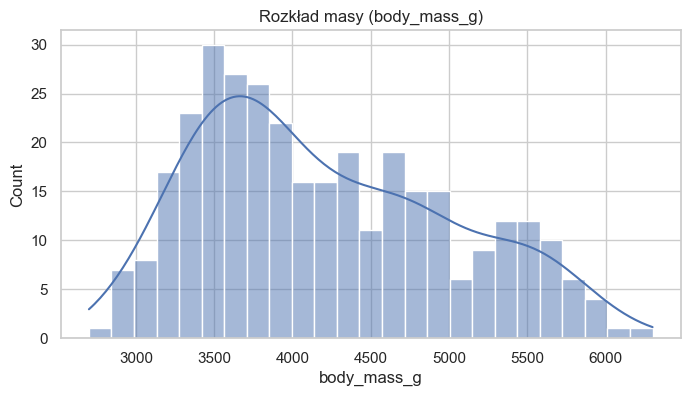

In [65]:

plt.figure(figsize=(8,4))
sns.histplot(data=d, x="body_mass_g", kde=True, bins=25)
plt.title("Rozkład masy (body_mass_g)")
plt.show()


Boxplot / violinplot (outliery i porównania)

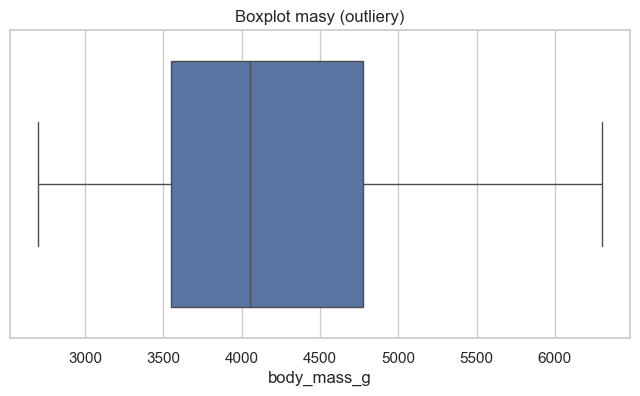

In [66]:
plt.figure(figsize=(8,4))
sns.boxplot(data=d, x="body_mass_g")
plt.title("Boxplot masy (outliery)")
plt.show()

| Element      | Znaczenie                | Interpretacja         |
| ------------ | ------------------------ | --------------------- |
| Pudełko      | Q1-Q3 (środek 50%)       | Gęstość danych        |
| Czarna linia | MEDIANA (50%)            | Typowa waga           |
| Wąsy         | Q1-1.5×IQR do Q3+1.5×IQR | "Normalny" zakres     |
| Kropki (o)   | Outliery (>1.5×IQR)      | Nietypowe pingwiny    |
| Gwiazdki (*) | Ekstremalne (>3×IQR)     | Naprawdę ciężkie/łeve |

In [68]:
df["body_mass_g"].describe()   # podsumowanie liczbowe

count     342.000000
mean     4201.754386
std       801.954536
min      2700.000000
25%      3550.000000
50%      4050.000000
75%      4750.000000
max      6300.000000
Name: body_mass_g, dtype: float64

In [69]:
Q1 = df['body_mass_g'].quantile(0.25)
Q3 = df['body_mass_g'].quantile(0.75)
IQR = Q3 - Q1
print(f"IQR = {IQR:.0f}g")  # np. IQR = 1200g


IQR = 1200g


In [70]:
stats = df['body_mass_g'].describe()
IQR = stats['75%'] - stats['25%']
print(f"IQR = {IQR:.0f}g")


IQR = 1200g



Dlaczego wąsy = min-max?
Seaborn whis=1.5 (domyślnie):

Wąsy idą do najdalszego punktu danych w granicach ±1.5*IQR

Jeśli wszystkie punkty mieszczą się w tym zakresie → wąsy = min-max

Dopiero punkty poza → kropki (outliery)
​

Wymuś wąsy dokładnie ±1.5*IQR:

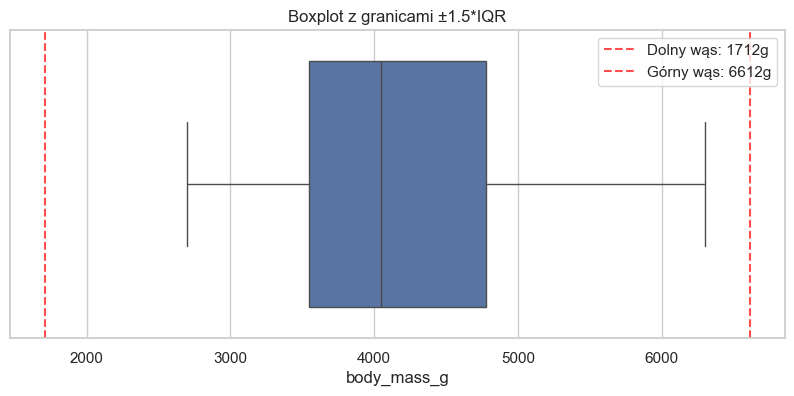

Granice wąsów: 1712g - 6612g
min/max danych: 2700g - 6300g


In [73]:
# Zakładając, że masz df = d z masą
# Oblicz granice IQR
Q1 = d['body_mass_g'].quantile(0.25)
Q3 = d['body_mass_g'].quantile(0.75)
IQR = Q3 - Q1
dolny = Q1 - 1.5 * IQR
górny = Q3 + 1.5 * IQR

# Filtruj dane (tylko w granicach wąsów)
d_filtered = d[(d['body_mass_g'] >= dolny) & (d['body_mass_g'] <= górny)]

# Rysuj z liniami granic
plt.figure(figsize=(10, 4))
sns.boxplot(data=d_filtered, x="body_mass_g")
plt.axvline(dolny, color='red', linestyle='--', alpha=0.7, label=f'Dolny wąs: {dolny:.0f}g')
plt.axvline(górny, color='red', linestyle='--', alpha=0.7, label=f'Górny wąs: {górny:.0f}g')
plt.title("Boxplot z granicami ±1.5*IQR")
plt.legend()
plt.show()

print(f"Granice wąsów: {dolny:.0f}g - {górny:.0f}g")
print(f"min/max danych: {d['body_mass_g'].min():.0f}g - {d['body_mass_g'].max():.0f}g")


Violin plot to rozszerzony boxplot – pokazuje histogram + KDE w formie symetrycznej "skrzypiec".

| Boxplot                         | Violin plot                     |
| ------------------------------- | ------------------------------- |
| 5 liczb (Q1, mediana, Q3, wąsy) | Pełny rozkład (histogram + KDE) |
| Pudełko + wąsy                  | Gładkie "skrzypce"              |
| Nie pokazuje multi-modalności   | Pokazuje kilka pików            |



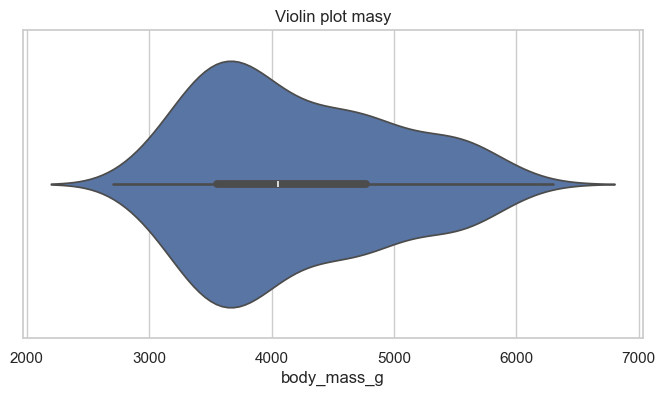

In [74]:
plt.figure(figsize=(8,4))
sns.violinplot(data=d, x="body_mass_g")
plt.title("Violin plot masy")
plt.show()


<Axes: xlabel='body_mass_g'>

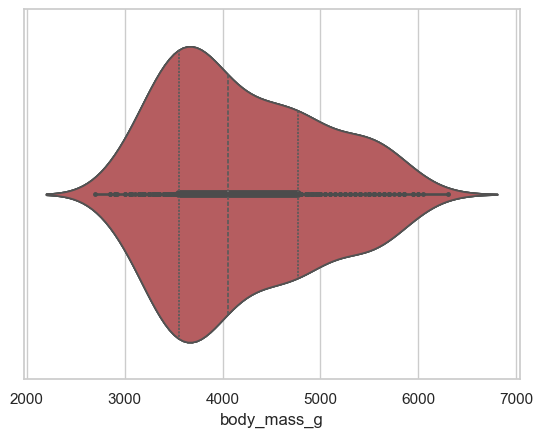

In [75]:
sns.violinplot(data=d, x="body_mass_g", inner="box")     # boxplot wewnątrz
sns.violinplot(data=d, x="body_mass_g", inner="quartile") # kwartyli
sns.violinplot(data=d, x="body_mass_g", inner="points")   # punkty danych
sns.violinplot(data=d, x="body_mass_g", inner=None)       # pusta skrzypiec



Praktyczny przykład (pingwiny wg gatunku):

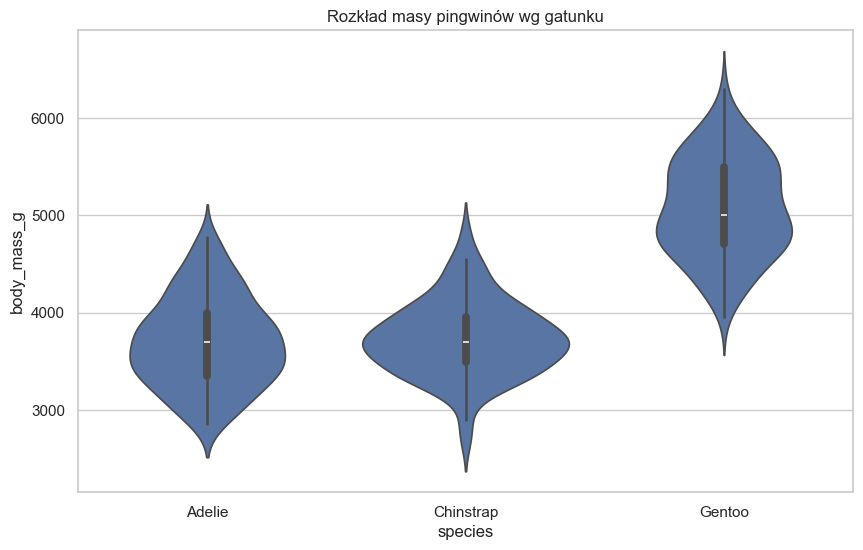

In [76]:
plt.figure(figsize=(10,6))
sns.violinplot(data=df, x="species", y="body_mass_g")
plt.title("Rozkład masy pingwinów wg gatunku")
plt.show()


<Axes: xlabel='species', ylabel='body_mass_g'>

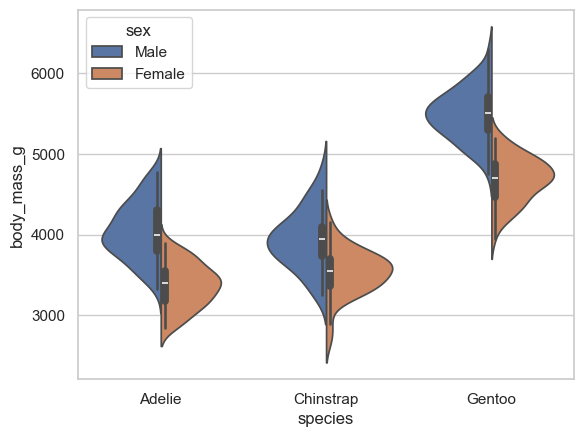

In [77]:
sns.violinplot(data=df, x="species", y="body_mass_g", hue="sex", split=True)
